# Evaluating a VLA: benchmarks, statistics, and sim-versus-real 📏
### What a success rate means, how much to trust it, and when a simulator predicts reality

**Code:** `src/Halo_VLA/vla_foundations/evaluation_stats.py` (`wilson_interval`, `mcnemar_exact`, `required_episodes`, `mmrv`, `classify_failures`) on top of `chunking.py` / `generalization.py` ·
**papers/benchmarks:** SIMPLER ([arXiv:2405.05941](https://arxiv.org/abs/2405.05941)), LIBERO ([2306.03310](https://arxiv.org/abs/2306.03310)), LIBERO-PRO ([2510.03827](https://arxiv.org/abs/2510.03827)), LIBERO-Plus ([2510.13626](https://arxiv.org/abs/2510.13626)), RoboCasa ([2406.02523](https://arxiv.org/abs/2406.02523)), BridgeData V2 ([2308.12952](https://arxiv.org/abs/2308.12952)).

Every claim in a VLA paper is a **success rate on some episodes of some benchmark**. This notebook is about reading those numbers critically and producing trustworthy ones:

| part | question | experiment |
|---|---|---|
| 1 | what do the standard **benchmarks** test, and what do they not? | a table, and a toy four-suite benchmark in the style of LIBERO |
| 2 | can a benchmark be **passed by memorisation**? | a memoriser and a generalist, standard vs perturbed |
| 3 | how much is a success rate **worth**? | confidence intervals, seed variance, paired tests, how many episodes you need |
| 4 | does **simulation predict reality**? | a SIMPLER-style study with Pearson `r` and MMRV |
| 5 | what do the **failures** look like? | success vs progress, and a failure taxonomy |

### Where this notebook corrects the usual summary
* **SIMPLER is not "a simulated manipulation benchmark" in the usual sense.** It is a set of simulated environments built to **predict the real-world ranking of policies** that were trained on real data (Google Robot, WidowX / Bridge), with two protocols (*Visual Matching*: the sim is made to look like the real scene; *Variant Aggregation*: average over many visual variants). It is validated by
  **Pearson correlation** and **Mean Maximum Rank Violation (MMRV)** between sim and real success over > 1500 paired evaluations; the paper reports for Google Robot, e.g., MMRV 0.056 and `r` = 0.924 for Visual Matching. Whether it is "the most commonly cited" benchmark depends on the community (LIBERO is at least as common); both are quoted constantly.
* **LIBERO** has four suites of 10 tasks (**Spatial**, **Object**, **Goal**, **Long** = LIBERO-10; plus LIBERO-90) with 50 demonstrations per task, and is **close to saturated** (> 95 % for recent models), which is exactly why LIBERO-PRO and LIBERO-Plus exist: they report that models collapse under modest perturbations of objects, layouts, instructions or camera, i.e. the standard numbers partly measure **memorisation**.
* "Open X-Embodiment eval set" is not a benchmark: OXE is a *training* collection; RT-X was evaluated on partner labs' own robots.
* **RoboCasa** (≈ 100 tasks over ≈ 120 kitchen scenes) and **BridgeData V2** (≈ 60K real WidowX trajectories, 24 environments; the standard *real-world* evaluation platform for OpenVLA-class models) are quoted from the papers and approximate.

| | published | this notebook |
|---|---|---|
| suites | LIBERO Spatial / Object / Goal / Long | the same four *kinds* of test in a toy world |
| episodes per number | 50 per task (LIBERO), 24-100 real trials | 96-400 scenes |
| sim vs real | SIMPLER on Google Robot / Bridge | clean vs shifted-and-noisy worlds |

# Part 1: A toy benchmark with four suites

## Step 1: What the four LIBERO suites test

| LIBERO suite | what varies, what is fixed | what it probes | toy analogue here |
|---|---|---|---|
| **Spatial** | same objects, different *layouts*; the instruction names a spatial relation | spatial reasoning | `go to left / right / top / bottom` |
| **Object** | same layout type, different *object identities* | object recognition / grounding | `go to <colour>` |
| **Goal** | the *same scene*, different goals | goal conditioning (language use) | one fixed layout, three goals |
| **Long** | multi-step tasks | long-horizon composition | `go to A` then `go to B` |

We train one generalist policy (early-fusion, the architecture that worked in the backbone notebook) on `Object` + `Spatial` data and evaluate it on all four.

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, SmolVLAConfig, SmolVLAPolicy, ToyVLM, VLMConfig, VLMPretrainer)
from open_vlas.evaluation import EmbodiedScenario
from pi_family import PiTrainer, PiVocabulary
from pi_family.toy import DemoGenerator, PointWorld
from pi_family.toy.world import COLORS, Scene
from vla_foundations.chunking import ChunkedRunner
from vla_foundations.encoders import ToyViT, caption_vocab
from vla_foundations.evaluation_stats import (bootstrap_difference, classify_failures, mcnemar_exact, mmrv, pearson, required_episodes, wilson_interval)
from vla_foundations.fusion import FusionConfig, FusionPolicy
from vla_foundations.generalization import run_chain
from vla_foundations.tasks import colour_demos, colour_scenarios, colour_scenarios_three, make_colour_demos_three, make_side_demos, make_side_scenarios

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld(); gen = DemoGenerator(world)
def dataset(episodes, chunk=16):
    return EmbodiedMixture([EmbodiedSource(world, episodes, EMBODIMENTS["point2d"], chunk_size=chunk)])
def run(policy, scenarios, chunk=16, k=8, noise=0.0, w=None, steps=50, transform=None):
    fn = (lambda b: policy.sample_actions(b)) if transform is None else (lambda b: policy.sample_actions(b.replace(images=transform(b.images))))
    return ChunkedRunner(w or world, chunk, k, action_noise=noise, max_steps=steps).run(fn, scenarios)

torch.manual_seed(0)
generalist = FusionPolicy(ToyViT().eval(), 64, FusionConfig(fusion="early"), caption_vocab())
colour_train, side_train = make_colour_demos_three(gen, 3000, np.random.default_rng(0)), make_side_demos(gen, 3000, np.random.default_rng(1))
tr = PiTrainer(generalist, dataset(colour_train + side_train), batch_size=64, lr=2e-3, grad_clip=10.0); tr.fit(5000); generalist.eval()
print(f"generalist trained in {tr.history.seconds:.0f} s")

generalist trained in 434 s


Object (colour)                    success 0.99   95% CI [0.97, 1.00]  (n = 200)
Spatial (left/right/top/bottom)    success 1.00   95% CI [0.98, 1.00]  (n = 200)
Goal (fixed layout, 3 goals)       success 1.00   95% CI [0.98, 1.00]  (n = 200)
Long (two skills)                  success 0.97   95% CI [0.94, 0.99]  (n = 200)


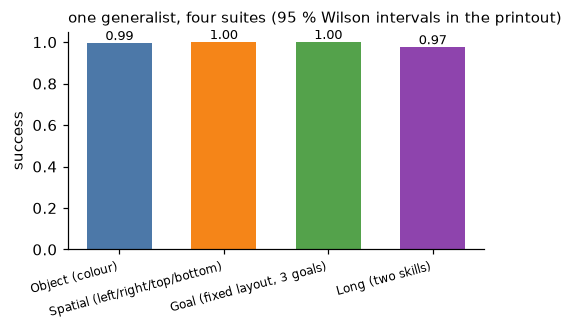

In [2]:
# the four suites
suites = {}
suites["Object (colour)"] = run(generalist, colour_scenarios_three(gen, 200, 123)).success
suites["Spatial (left/right/top/bottom)"] = run(generalist, make_side_scenarios(gen, 200, 321)).success
# Goal: ONE fixed layout, the goal changes (the same scene as in the 'memoriser' below)
layout_rng = np.random.default_rng(77)
FIXED = world.sample_scene(layout_rng, colors=["red", "green", "blue"])
def goal_scenes(n, seed, jitter=0.0, start_jitter=0.03):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        objs = {c: np.clip(xy + rng.uniform(-jitter, jitter, 2), 0.08, 0.92).astype(np.float32) for c, xy in FIXED.objects.items()}
        start = np.clip(FIXED.robot + rng.uniform(-start_jitter, start_jitter, 2), 0.05, 0.95).astype(np.float32)
        target = str(rng.choice(list(COLORS)))
        out.append(EmbodiedScenario(Scene(objs, start), f"go to {target}", target, "point2d"))
    return out
suites["Goal (fixed layout, 3 goals)"] = run(generalist, goal_scenes(200, 5)).success
# Long: chains of two skills with a scripted planner
rng_l = np.random.default_rng(9); ls, seqs = [], []
for _ in range(200):
    sc = world.sample_scene(rng_l, colors=list(rng_l.permutation(list(COLORS)))); ls.append(EmbodiedScenario(sc, "chain", "red", "point2d")); seqs.append([str(c) for c in rng_l.permutation(list(COLORS))[:2]])
suites["Long (two skills)"] = run_chain(world, generalist.sample_actions, ls, seqs, per_skill_steps=30) >= 2
for name, ok in suites.items():
    lo, hi = wilson_interval(int(ok.sum()), len(ok))
    print(f"{name:34s} success {ok.mean():.2f}   95% CI [{lo:.2f}, {hi:.2f}]  (n = {len(ok)})")
plots.bar_compare({k: float(v.mean()) for k, v in suites.items()}, "success", "one generalist, four suites (95 % Wilson intervals in the printout)", ylim=(0, 1.05), colors=["#4c78a8", "#f58518", "#54a24b", "#8e44ad"], rotate=15)

**All four suites are passed** (0.97-1.00, narrow intervals): exactly the situation of LIBERO today. A saturated benchmark can no longer rank anything: the difference between a good and a better policy has to be found elsewhere. The next test shows that even a *perfect score* can mean very little.

# Part 2: Can a benchmark be passed by memorisation?

## Step 2: A memoriser and a generalist

LIBERO-PRO and LIBERO-Plus report that models scoring > 90 % on standard LIBERO collapse when the layout, the objects' positions or the instructions are perturbed slightly. The mechanism is easy to build. A **memoriser** is trained on **one fixed layout** (the `Goal` suite: three goals, the robot starting near the same place), a **generalist** on random layouts.
We test both on the *standard* evaluation (the training layout, as the benchmark does), then **perturb** it: move the objects by up to ±0.12, or start the robot far away.

memoriser (1 layout)           standard (training layout) 1.00 | objects moved ±0.12 0.17 | robot starts far away 0.17


generalist (random layouts)    standard (training layout) 0.99 | objects moved ±0.12 0.94 | robot starts far away 1.00


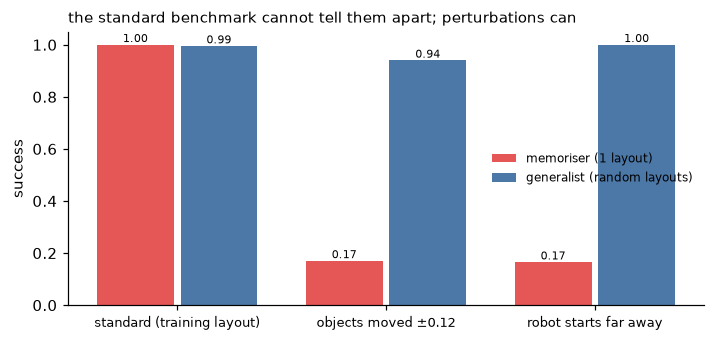

In [3]:
# memoriser demonstrations: the fixed layout, three goals, small start jitter
rng_m = np.random.default_rng(0); mem_demos = []
for _ in range(600):
    target = str(rng_m.choice(list(COLORS)))
    start = np.clip(FIXED.robot + rng_m.uniform(-0.03, 0.03, 2), 0.05, 0.95).astype(np.float32)
    mem_demos.append(gen.demo("reach", rng_m, "expert", task=(Scene(dict(FIXED.objects), start), f"go to {target}", [target], [target])))
torch.manual_seed(0)
memoriser = FusionPolicy(ToyViT().eval(), 64, FusionConfig(fusion="early"), caption_vocab())
PiTrainer(memoriser, dataset(mem_demos), batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000); memoriser.eval()
torch.manual_seed(0)
broad = FusionPolicy(ToyViT().eval(), 64, FusionConfig(fusion="early"), caption_vocab())
PiTrainer(broad, dataset(colour_train), batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000); broad.eval()
tests = {"standard (training layout)": goal_scenes(200, 5), "objects moved ±0.12": goal_scenes(200, 6, jitter=0.12),
         "robot starts far away": goal_scenes(200, 7, start_jitter=0.35)}
table = {}
for pname, pol in (("memoriser (1 layout)", memoriser), ("generalist (random layouts)", broad)):
    table[pname] = {k: run(pol, s).success.mean() for k, s in tests.items()}
    print(f"{pname:30s} " + " | ".join(f"{k} {v:.2f}" for k, v in table[pname].items()), flush=True)
plots.grouped_bars({k: {p: table[p][k] for p in table} for k in tests}, "success", "the standard benchmark cannot tell them apart; perturbations can", colors=["#e45756", "#4c78a8"])

The **memoriser scores 1.00 on the standard test** (its own training layout), the same as the generalist (0.99): the standard benchmark **cannot tell them apart**. Move the objects by ±0.12 or start the robot far away and the memoriser falls to **0.17** while the generalist keeps 0.94-1.00. This is the mechanism behind LIBERO-PRO's "> 90 % to ≈ 0 %": a policy trained on a fixed layout does not need to *see* the scene.
**A benchmark number is only as informative as the perturbations it survived.**

# Part 3: How much is a success rate worth?

## Step 3: Confidence intervals

A success rate over `n` independent episodes is a binomial proportion. The **Wilson interval** is the right way to put an interval on it (the textbook normal interval is wrong near 0 and 1 and for small `n`). We show how wide it is for the sizes people actually use.

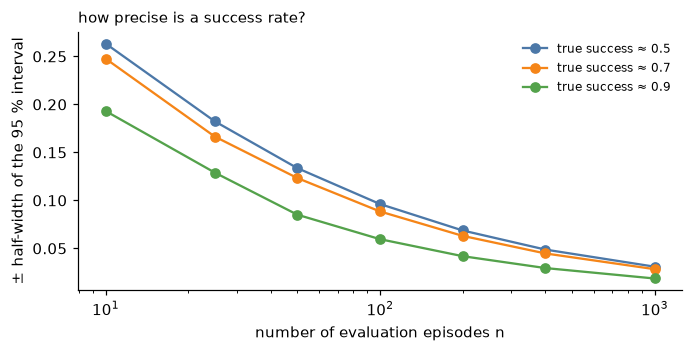

{10: (0.4, 0.89), 50: (0.56, 0.81), 100: (0.6, 0.78), 400: (0.65, 0.74)} ← intervals for a success rate of 0.70
episodes per policy needed to detect 0.70 vs 0.75 (5 points) with 80 % power: 1251 | 0.70 vs 0.80: 294 | 0.70 vs 0.90: 62


In [4]:
ns = [10, 25, 50, 100, 200, 400, 1000]
fig, ax = plt.subplots(figsize=(6.4, 3.3))
for p, col in ((0.5, "#4c78a8"), (0.7, "#f58518"), (0.9, "#54a24b")):
    ax.plot(ns, [(wilson_interval(int(round(p * n)), n)[1] - wilson_interval(int(round(p * n)), n)[0]) / 2 for n in ns], "o-", color=col, label=f"true success ≈ {p}")
ax.set_xscale("log"); ax.set_xlabel("number of evaluation episodes n"); ax.set_ylabel("± half-width of the 95 % interval"); ax.legend(fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("how precise is a success rate?", fontsize=10, loc="left")
plt.tight_layout(); plt.show()
print({n: tuple(round(v, 2) for v in wilson_interval(int(0.7 * n), n)) for n in (10, 50, 100, 400)}, "← intervals for a success rate of 0.70")
print("episodes per policy needed to detect 0.70 vs 0.75 (5 points) with 80 % power:", required_episodes(0.70, 0.75), "| 0.70 vs 0.80:", required_episodes(0.70, 0.80), "| 0.70 vs 0.90:", required_episodes(0.70, 0.90))

At `n = 50` (LIBERO's number of trials per task) a measured 70 % means "somewhere between 56 % and 81 %". **Detecting a 5-point improvement needs more than a thousand episodes per policy**; 10 points needs ≈ 300. Papers that report 3-point gains from 50 trials per task, averaged over a few tasks, are reporting numbers that are mostly noise unless the evaluation is *paired* (Step 5).

## Step 4: But the *episodes* are not the only noise: training seeds

The interval above covers the randomness of the evaluation scenes for **one trained model**. A second source is the **training run**: same recipe, different seed. We train the same policy with four seeds and evaluate all on the **same** 200 scenes.

In [5]:
rec_demos = colour_demos(gen, 1500, np.random.default_rng(3))
eval_scen = colour_scenarios(gen, 200, 99)
vlm = ToyVLM(VLMConfig(), PiVocabulary()); VLMPretrainer(vlm, world).fit(1500)
seed_models, seed_success = [], []
for seed in range(4):
    torch.manual_seed(seed)
    p = SmolVLAPolicy(vlm, SmolVLAConfig(chunk_size=1, objective="mse"))
    PiTrainer(p, dataset(rec_demos, 1), batch_size=64, lr=2e-3, grad_clip=10.0, seed=seed).fit(2000); p.eval()
    ok = run(p, eval_scen, chunk=1, k=1).success
    seed_models.append(p); seed_success.append(ok)
    lo, hi = wilson_interval(int(ok.sum()), len(ok))
    print(f"training seed {seed}: success {ok.mean():.2f}  (evaluation-only 95% interval [{lo:.2f}, {hi:.2f}])", flush=True)
rates = [s.mean() for s in seed_success]
print(f"mean {np.mean(rates):.2f}, std across seeds {np.std(rates, ddof=1):.3f}  (the binomial noise of 200 episodes alone would give ±{np.sqrt(np.mean(rates) * (1 - np.mean(rates)) / 200):.3f})")

training seed 0: success 0.39  (evaluation-only 95% interval [0.32, 0.45])


training seed 1: success 0.35  (evaluation-only 95% interval [0.29, 0.42])


training seed 2: success 0.26  (evaluation-only 95% interval [0.20, 0.32])


training seed 3: success 0.25  (evaluation-only 95% interval [0.20, 0.31])


mean 0.31, std across seeds 0.067  (the binomial noise of 200 episodes alone would give ±0.033)


Four runs of **the same recipe** differ by 14 points (0.25 to 0.39), a standard deviation of **0.067**, twice what evaluation noise alone predicts for 200 episodes (±0.033): the training run contributes about as much noise as the scenes do (≈ 0.06 of its own after removing the evaluation part). This policy is deliberately small-budget (so the absolute level is low), but the lesson is general: **a "3-point improvement" from one training run each is not evidence**.

## Step 5: Paired comparison

When two policies are evaluated on the **same episodes**, only the episodes on which they *disagree* carry information; a **paired** test (McNemar for success/failure, or a bootstrap over episodes) is much more powerful than comparing two independent proportions. We compare two of the seeds.

In [6]:
a, b = seed_success[int(np.argmax(rates))], seed_success[int(np.argmin(rates))]
n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
la, ha = wilson_interval(int(a.sum()), len(a)); lb, hb = wilson_interval(int(b.sum()), len(b))
p_pair = mcnemar_exact(a, b)
lo, hi = bootstrap_difference(a, b)
print(f"best seed {a.mean():.2f} vs worst seed {b.mean():.2f} on the same {len(a)} scenes")
print(f"unpaired: intervals [{la:.2f}, {ha:.2f}] and [{lb:.2f}, {hb:.2f}] {'overlap' if max(la, lb) <= min(ha, hb) else 'do not overlap'}")
print(f"paired: A-only successes {n10}, B-only successes {n01} → exact McNemar p = {p_pair:.4f} | bootstrap 95% interval of the difference [{lo:+.3f}, {hi:+.3f}]")

best seed 0.39 vs worst seed 0.25 on the same 200 scenes
unpaired: intervals [0.32, 0.45] and [0.20, 0.31] do not overlap
paired: A-only successes 45, B-only successes 18 → exact McNemar p = 0.0009 | bootstrap 95% interval of the difference [+0.060, +0.210]


Even paired, the best and worst seed of an *identical* recipe differ **significantly** (45 episodes only the best succeeds, 18 only the worst; exact McNemar `p = 0.001`, bootstrap interval of the gap +6 to +21 points). That is a difference that is **real for these two trained models**, and meaningless as a statement about the *recipe*: it is seed luck. Two cautions: (i) we picked the extremes of four seeds, which inflates any comparison;
(ii) significance of one model's score against another's says nothing about which *recipe* is better: for that you need several seeds per recipe and a test across seeds.

# Part 4: Does simulation predict reality?

## Step 6: A SIMPLER-style study

SIMPLER's claim is about *rankings*: if policy A beats policy B in the simulator, does it beat it in reality? They quantify it with the **Pearson correlation** between sim and real success rates and the **Mean Maximum Rank Violation**
$$\text{MMRV} = \frac1N \sum_{i}\; \max_{j:\ (s_i - s_j)(r_i - r_j) < 0} |r_i - r_j|,$$
the average, over policies, of the largest *real* performance gap among pairs that the sim ranks the wrong way round (0 = never mis-ranks; small = only mis-ranks policies that are close in reality).

Our version: **six policies** (the early-fusion policy of Step 1 on a frozen random vision encoder: excellent on clean images, fragile to appearance shifts) with different training recipes (data size, with / without appearance augmentation), a "**real**" world that is *shifted and noisy* (appearance shift 1.0 plus execution noise 0.3), and three simulators of increasing **fidelity**: the *clean* sim, a *partially matched* sim (half the appearance shift, no noise), and a *matched* sim (the same appearance shift, no noise: SIMPLER's "Visual Matching" in spirit).

In [7]:
def appearance_shift(x, strength=1.0, seed=None):
    g = torch.Generator().manual_seed(int(np.random.randint(1 << 30)) if seed is None else seed); b = x.shape[0]
    chan = 1 + strength * 0.25 * (2 * torch.rand(b, 3, 1, 1, generator=g) - 1); bias = strength * 0.1 * (2 * torch.rand(b, 1, 1, 1, generator=g) - 1)
    return (x * chan + bias + strength * 0.06 * torch.randn(x.shape, generator=g)).clamp(0, 1)
class AugData:                                  # wraps a dataset: every training image gets a random appearance shift
    def __init__(self, base, strength): self.base, self.strength = base, strength
    def sample(self, n, rng):
        b = self.base.sample(n, rng); return b.replace(images=appearance_shift(b.images, self.strength))
recipes = {"300 demos": (300, 0.0), "1000 demos": (1000, 0.0), "3000 demos": (3000, 0.0), "300 demos + aug": (300, 1.0), "1000 demos + aug": (1000, 1.0), "3000 demos + aug": (3000, 1.0)}
sim_eval = colour_scenarios(gen, 200, 555)
worlds = {"sim: clean": dict(), "sim: half-matched (shift 0.5)": dict(transform=lambda x: appearance_shift(x, 0.5, seed=1)),
          "sim: matched (shift 1.0)": dict(transform=lambda x: appearance_shift(x, 1.0, seed=1)), "REAL: shift 1.0 + noise 0.3": dict(transform=lambda x: appearance_shift(x, 1.0, seed=2), noise=0.3)}
scores = {k: {} for k in worlds}
trained = {}
for name, (n, aug) in recipes.items():
    torch.manual_seed(0)
    p = FusionPolicy(ToyViT().eval(), 64, FusionConfig(fusion="early"), caption_vocab())     # frozen random vision: excellent on clean images, fragile to appearance shifts
    base = dataset(colour_demos(gen, n, np.random.default_rng(100 + n)))
    PiTrainer(p, AugData(base, aug) if aug else base, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000); p.eval()
    trained[name] = p
    for wname, kw in worlds.items():
        scores[wname][name] = run(p, sim_eval, **kw).success.mean()
    print(f"{name:18s} " + " | ".join(f"{k.split(':')[0]}{':' + k.split(':')[1][:14] if ':' in k else ''} {scores[k][name]:.2f}" for k in worlds), flush=True)

300 demos          sim: clean 0.03 | sim: half-matched  0.02 | sim: matched (shif 0.04 | REAL: shift 1.0 + n 0.02


1000 demos         sim: clean 0.96 | sim: half-matched  0.62 | sim: matched (shif 0.26 | REAL: shift 1.0 + n 0.41


3000 demos         sim: clean 0.96 | sim: half-matched  0.49 | sim: matched (shif 0.28 | REAL: shift 1.0 + n 0.40


300 demos + aug    sim: clean 0.05 | sim: half-matched  0.07 | sim: matched (shif 0.09 | REAL: shift 1.0 + n 0.09


1000 demos + aug   sim: clean 0.96 | sim: half-matched  0.94 | sim: matched (shif 0.92 | REAL: shift 1.0 + n 0.95


3000 demos + aug   sim: clean 0.94 | sim: half-matched  0.97 | sim: matched (shif 0.94 | REAL: shift 1.0 + n 0.98


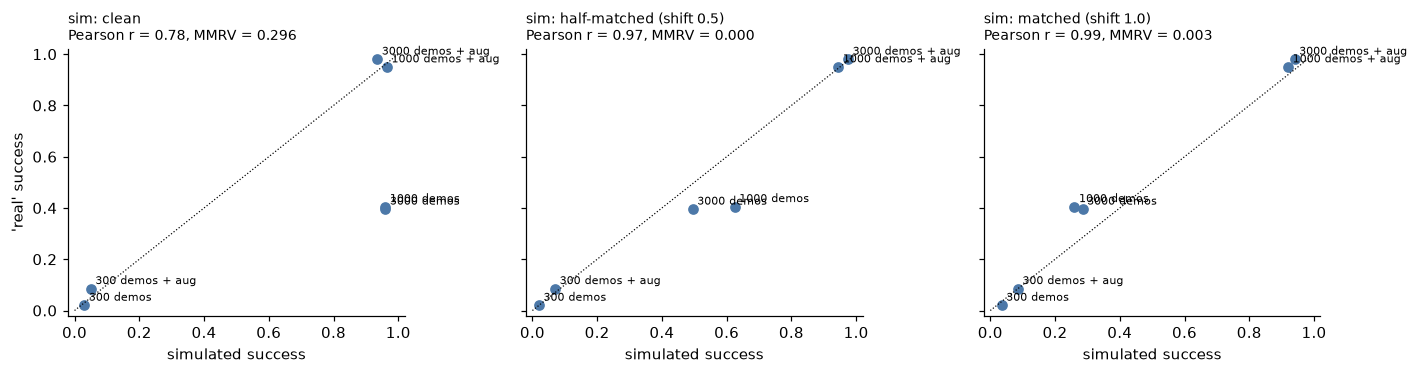

{'sim: clean': (0.783, np.float64(0.296)), 'sim: half-matched (shift 0.5)': (0.974, 0.0), 'sim: matched (shift 1.0)': (0.988, np.float64(0.003))} ← (Pearson r, MMRV)


In [8]:
names = list(recipes)
real = [scores["REAL: shift 1.0 + noise 0.3"][n] for n in names]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
summary = {}
for ax, wname in zip(axes, ("sim: clean", "sim: half-matched (shift 0.5)", "sim: matched (shift 1.0)")):
    sim = [scores[wname][n] for n in names]
    summary[wname] = (pearson(sim, real), mmrv(sim, real))
    ax.scatter(sim, real, color="#4c78a8")
    for n, x, y in zip(names, sim, real):
        ax.annotate(n, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.plot([0, 1], [0, 1], ":", color="k", lw=0.8); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_xlabel("simulated success"); ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"{wname}\nPearson r = {summary[wname][0]:.2f}, MMRV = {summary[wname][1]:.3f}", fontsize=9, loc="left")
axes[0].set_ylabel("'real' success")
plt.tight_layout(); plt.show()
print({k: (round(v[0], 3), round(v[1], 3)) for k, v in summary.items()}, "← (Pearson r, MMRV)")

**What the measurements say** (200 scenes per number).

* The six policies split into two groups: the policies trained on **1000-3000 demonstrations without augmentation** are perfect on clean images (0.96) but fall to ≈ 0.40 in the "real" shifted-and-noisy world; the ones **with augmentation** stay at 0.95-0.98. (The 300-demonstration policies are not trained enough to work anywhere.)
* The **clean simulator** cannot see that difference: it ranks the non-augmented policies *above or equal to* the augmented ones (0.96 vs 0.96 / 0.94), the opposite of reality: **Pearson `r` = 0.78 and MMRV = 0.30**: the simulator mis-ranks policies that differ by **0.5 in reality**.
* With a **half-matched** simulator (half the appearance shift) the agreement is already excellent (`r` = 0.97, MMRV = 0.00) and with a **matched** one `r` = 0.99, MMRV = 0.003. This is SIMPLER's *Visual Matching* idea in miniature: you do not need a perfect simulator, you need one that reproduces **the factors that distinguish the policies you are comparing**. Add it to the evaluation protocol and the simulator becomes predictive.
* The flip side: a *clean* simulator is a poor predictor of robustness. Policies that look equal in simulation can differ enormously on a real camera, which is what a sim benchmark with unmatched visuals hides.

# Part 5: What do failures look like?

## Step 7: Success is a coarse metric

Success is binary; a policy that stops 6 cm from a 5 cm target gets the same zero as one that never leaves the start. **Progress** (`1 − final distance / initial distance`) and a **failure taxonomy** (wrong object / near miss / lost) say *how* a policy fails, which is what you need to fix it. We apply both to the same policies in the "real" world of Step 6.

300 demos          success 0.03 | progress -0.13 | failures: {'wrong object': 1, 'near miss': 5, 'lost': 188, 'failures': 194}


1000 demos         success 0.34 | progress +0.52 | failures: {'wrong object': 0, 'near miss': 19, 'lost': 114, 'failures': 133}


3000 demos         success 0.34 | progress +0.41 | failures: {'wrong object': 0, 'near miss': 17, 'lost': 115, 'failures': 132}


300 demos + aug    success 0.08 | progress +0.04 | failures: {'wrong object': 0, 'near miss': 8, 'lost': 176, 'failures': 184}


1000 demos + aug   success 0.94 | progress +0.91 | failures: {'wrong object': 0, 'near miss': 8, 'lost': 4, 'failures': 12}


3000 demos + aug   success 0.95 | progress +0.92 | failures: {'wrong object': 0, 'near miss': 7, 'lost': 3, 'failures': 10}


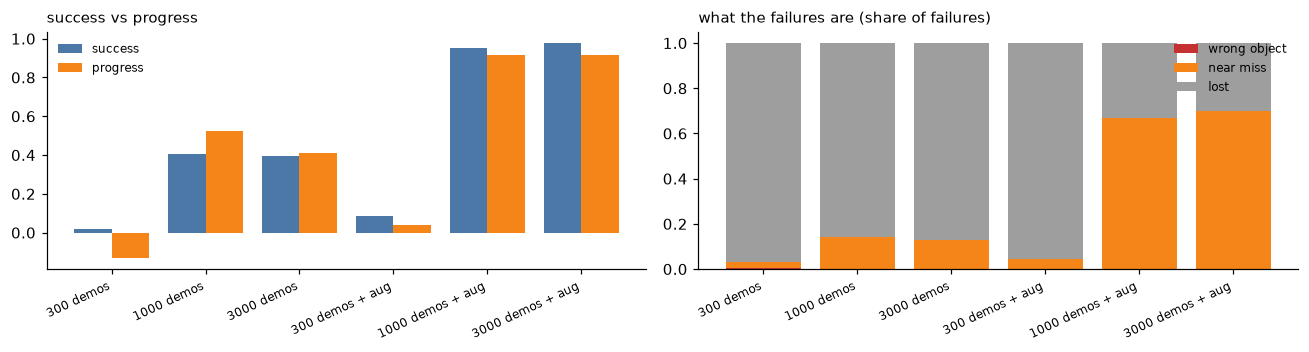

In [9]:
progress, tax = {}, {}
for name, p in trained.items():
    r = run(p, sim_eval, transform=lambda x: appearance_shift(x, 1.0, seed=2), noise=0.3)
    goal = np.stack([s.scene.objects[s.target] for s in sim_eval]); start = np.stack([s.scene.robot for s in sim_eval])
    progress[name] = float(np.mean(1 - np.linalg.norm(r.trajectories[:, -1] - goal, axis=1) / np.linalg.norm(start - goal, axis=1)))
    others = [np.stack([xy for c, xy in s.scene.objects.items() if c != s.target]) for s in sim_eval]
    tax[name] = classify_failures(r.trajectories, r.steps, r.success, goal, others)
    print(f"{name:18s} success {r.success.mean():.2f} | progress {progress[name]:+.2f} | failures: {tax[name]}", flush=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
axes[0].bar(range(len(names)), [scores['REAL: shift 1.0 + noise 0.3'][n] for n in names], 0.4, label="success", color="#4c78a8"); axes[0].bar(np.arange(len(names)) + 0.4, [progress[n] for n in names], 0.4, label="progress", color="#f58518")
axes[0].set_xticks(np.arange(len(names)) + 0.2); axes[0].set_xticklabels(names, rotation=25, ha="right", fontsize=8); axes[0].legend(fontsize=8, frameon=False); axes[0].set_title("success vs progress", fontsize=10, loc="left")
bottom = np.zeros(len(names))
for kind, col in (("wrong object", "#c53030"), ("near miss", "#f58518"), ("lost", "#9e9e9e")):
    vals = np.array([tax[n][kind] / max(tax[n]["failures"], 1) for n in names]); axes[1].bar(range(len(names)), vals, bottom=bottom, label=kind, color=col); bottom += vals
axes[1].set_xticks(range(len(names))); axes[1].set_xticklabels(names, rotation=25, ha="right", fontsize=8); axes[1].legend(fontsize=8, frameon=False); axes[1].set_title("what the failures are (share of failures)", fontsize=10, loc="left")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

* **Progress separates what success ties.** The 1000- and 3000-demonstration policies without augmentation both succeed 0.34 under the shift, but their progress is +0.52 vs +0.41; the 300-demonstration policy has success 0.03 and progress **−0.13** (it moves *away* from the target). Success saturates at 0 and 1; progress keeps resolving differences.
* **Almost no failure is a wrong object** (0-1 in every row): the policies are not confused about *which* object, they fail on **perception or precision**: the non-augmented ones are mostly *lost* (they wander: 114-188 failures), the augmented ones that remain are *near misses* (7-8 failures). A report of "93 % success" would hide this; the taxonomy says where to put the effort (robustness of vision for the first group, final-approach precision for the second).

## Step 8: A checklist, and recap

**Reporting checklist** (everything above in one list): (1) state `n` and give a **Wilson interval**, not a bare number; (2) report **training-seed variance** (≥ 3 seeds) when claiming a few points; (3) compare policies on the **same episodes** (paired) and report the paired test; (4) evaluate under **perturbations** (layout, objects, instruction, camera) in addition to the standard suite;
(5) report **progress / partial credit** and a **failure breakdown**, not only success; (6) for sim-vs-real claims report **Pearson `r` and MMRV** against real trials, and say how well the sim is matched; (7) never tune on the test scenes.

**Take-aways.** (1) The four LIBERO suites probe different abilities (spatial relations, object identity, goal use, horizon); a single average hides which. (2) A benchmark with a fixed layout can be passed by **memorisation**: the standard score is identical for a memoriser and a generalist, perturbations separate them. (3) With 50 trials a success rate is ±12 points; detecting 5 points needs ≈ 10³ episodes per policy; **training seeds** add as much noise as the evaluation scenes.
(4) A simulator is a *measurement instrument for rankings*: its quality is `r` and MMRV against real trials, and it improves as the sim is **matched** to reality. (5) Look at *how* policies fail.

### 🧪 Exercises
1. Repeat Step 4 with 8 seeds and a *different* recipe (e.g. LoRA vs full fine-tuning from the fine-tuning notebook): is the recipe difference larger than the seed std?
2. In Step 6 add a fifth world: sim with a *wrong* correction (shift of the opposite sign): does matching the wrong thing hurt `r` below the clean sim?
3. Add a *language-perturbed* suite (instruction swapped to a different object) and check whether the memoriser and the generalist differ (see the generalisation notebook).
4. Estimate by simulation how often a 5-point improvement at `n = 100` is declared significant (p < 0.05) by an unpaired z-test vs by a paired McNemar test on the same scenes.